<div class="alert alert-danger" role="alert">
  Note: <br>
    1. Only modify the area marked by "YOUR CODE STARTS HERE" and "YOUR CODE ENDS HERE" markers<br>
    2. If you are working locally, the data files should be in the same directory as your Assignment2.ipynb Notebook.<br>
</div>

## Assignment 2: Sentiment Analysis

The goal of this assignment is to train a machine learning model that can predict the sentiment of short statements as either negative, positive or neutral. To train your model, split the attached training data into training, validation and test sets, and train a multi-class logistic regression classifier using the training data. Tune the hyperparameters of the model using the validation set, and finally once all the hyperparameters are tuned and you selected your best model, test it on the test data and report its performance using the different metrics used for evaluating multi-class classifiers.

We'll use a multi-class logistic  regression classifier and go through the following steps:
 1. Loading and cleaning the data
 2. Splitting the data into training, validation, and test sets
 3. Preprocessing the text data
 4. Representing the data using TF-IDF
 5. Training a classifier
 6. Hyperparameter tuning
 7. Model selection and testing

# Import Libraries

In [ ]:
import pandas as pd

import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, learning_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

import matplotlib.pyplot as plt

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

###>>Cell # 1 (above) job:   Importing all needed functions, tools, modules, algorithms for our project

### Loading the data


Load the data.csv file

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
DATA_DIR = '/content/drive/MyDrive/Colab Notebooks'
data = pd.read_csv(os.path.join(DATA_DIR, 'data.csv'))

print(data.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
                                                text    sentiment
0   Enjoying a beautiful day at the park!        ...   Positive  
1   Traffic was terrible this morning.           ...   Negative  
2   Just finished an amazing workout! 💪          ...   Positive  
3   Excited about the upcoming weekend getaway!  ...   Positive  
4   Trying out a new recipe for dinner tonight.  ...   Neutral   


###>>Importing data from Drive and publishing its first 5 lines-rows


Here we are not 'publishing' rather simply displaying the first 5 rows of the dataframe (you can tweak method `head()` to adjust the number of rows displayed; for example `head(1)` will only display one row)

### Cleaning the data

Clean inconsistent data labels

In [ ]:
data['sentiment'].unique()
data['sentiment'] = data['sentiment'].str.strip()

Remove duplicates and missing values from your dataset

In [ ]:
print(data.isnull().sum())
data = data.dropna()
print(data.duplicated().sum())
data = data.drop_duplicates()

text         0
sentiment    0
dtype: int64
25


###>>25 duplicates removed (This phase I didn't understand what happened in detail, please Hassan I need insight &extra info: is it as simple as mentioned ?(=no further details relevant mentioning?); or else If background activity happened.. please intervene with clarification. Thanks)




Not really sure what's your exact question.

For the cleaning part, we are doing basic cleaning on our dataset:
* `.str.strip()`: We are using `.str.strip()` to prevent the creation of "unreal" or inflated classes by ensuring that values like "positive " and "positive" are treated as a single, consistent class. Check `data['sentiment'].value_counts()` before stripping.
* `.dropna()`: We are dropping rows that have any null (or NaN) values, as incomplete data can cause errors or bias the model's performance.
* `.drop_duplicates()`: We are dropping any duplicated rows found in the dataset. This is a straightforward process where the system scans each row and removes any that are an **exact match** to a row it has already seen, ensuring each record is unique.

We remove duplicated rows (records) to prevent the following:

1.  **Preventing Overfitting and Bias**: Duplicate rows can cause the model to give undue importance to specific instances, making it memorize the training data rather than learning general patterns. This leads to **overfitting**.
2.  **Accurate Performance Evaluation**: If duplicate records exist in both the training and test sets, the model's performance metrics will be artificially inflated, giving a misleadingly positive view of its real-world accuracy.
3.  **Improving Computational Efficiency**: Training on a dataset with many duplicates is inefficient as the algorithm performs redundant calculations. Removing them reduces the dataset size and speeds up training without sacrificing quality.

### Splitting the data

Split your dataset into train (80%), validation (10%) and test (10%) sets

In [ ]:
X = data['text']
y = data['sentiment']

In [ ]:
X_train, x_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42)

###>>At first 20% of the data given(temporarely) to test, so 80% remains for training.
###>>Last code line 50% of the 20% are partitioned for test so 10% remains for validation

### Pre-processing the data

 Pre-process your data by converting all characters to lowercase, removing stop words and performing stemming

In [ ]:
def preprocess_text(text):
    text = text.lower()

    tokens = nltk.word_tokenize(text)

    stop_words = set(stopwords.words('english'))
    ps = PorterStemmer()
    tokens = [ps.stem(token) for token in tokens if token not in stop_words]

    return ' '.join(tokens)

In [ ]:
X_train_processed = X_train.apply(preprocess_text)
X_val_processed = X_val.apply(preprocess_text)
X_test_processed = X_test.apply(preprocess_text)

###>> Another phase of preparing the data (after cleaning). And tokenization: like each 3-4 letters become a particle of data.

The avove cells performs tokenization, which is the process of breaking text into individual words or "tokens" (like 'apple' or 'banana'), not fixed-length letter groups, which are then used for analysis.

### Representing the data using TF-IDF

Transform your pre-processed data into tf-idf vectors using the **TfidfVectorizer** of the **sklearn** library. *Note:* You should first transform the training data into TF-IDF vectors, and then when transforming the validation and test data, you should make sure that the IDF scores for test instances are deduced from the training data to avoid data leakage.

In [ ]:
tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_processed)

X_val_tfidf = tfidf_vectorizer.transform(X_val_processed)
X_test_tfidf = tfidf_vectorizer.transform(X_test_processed)


###>>Each data category (val,test,tarining) is vectorized separately; so the idf test scores are not added to the results of the idf training data scores

Each dataset (training, validation, and test) is transformed into a TF-IDF matrix
However, the vectorizer is only fit on the training data.
1. `fit_transform` on `X_train_processed`: This step is where all the "learning" happens. The vectorizer analyzes all the words in the training set to build its vocabulary and calculate the Inverse Document Frequency (IDF) scores. Think of this as the vectorizer creating a "rulebook" based on the training data.

2. `transform` on `X_val_processed` and `X_test_processed`: For these sets, the vectorizer doesn't learn anything new. It simply applies the exact same rulebook (vocabulary and IDF scores) it learned from the training data to convert the text into TF-IDF scores.

If you were to fit the vectorizer on each dataset separately, you would be letting information from the validation and test sets "leak" into your model's feature engineering. This is called data leakage, and it's a major problem. By fitting only on the training data, we ensure a fair and accurate evaluation of how the model will perform on truly unseen data.

### Training a classifier

Train a multi-class logistic regression model to predict the sentiment of statements into either negative, positive or neutral.You should use the **"sentiment"** column as the target variable and all the remaining **TF-IDF features**' columns created above as independent variables.


In [ ]:
clf = LogisticRegression()

clf.fit(X_train_tfidf, y_train)

val_predictions = clf.predict(X_val_tfidf)

val_accuracy = accuracy_score(y_val, val_predictions)

print(f"Validation Accuracy: {val_accuracy}")

Validation Accuracy: 0.8309859154929577


###>>Not a bad score, preliminary indicator that the model predicting fairly well in training

0.83 score indicates how well the model is performing on the **validation data**, not the **training data**. We use a separate validation set to see how well the model generalizes to new information it hasn't seen before.
Think of it like this: the model learns on the training data (studying), but we test it on the validation data (a practice quiz) to see if it actually understood the material and didn't just memorize the answers. The 0.83 score shows it's doing well on that quiz.

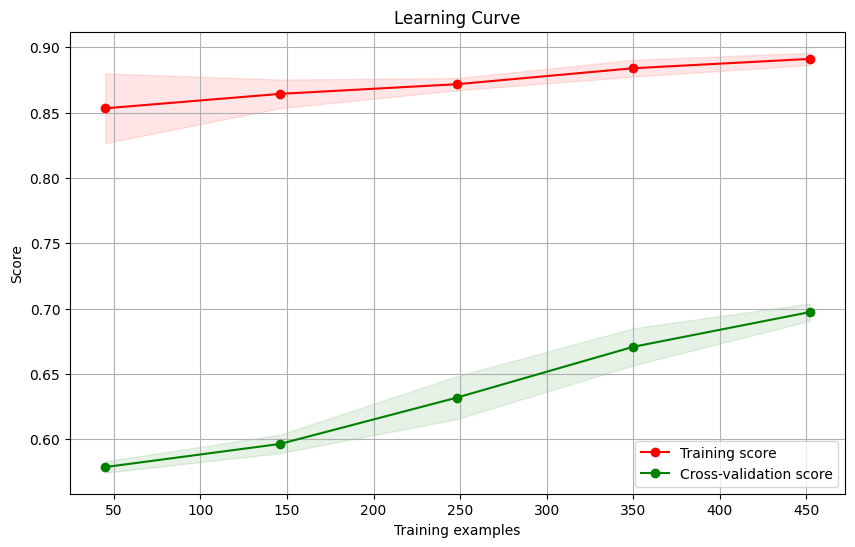

In [ ]:
def plot_learning_curve(estimator, X, y, cv=5):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=-1, train_sizes=np.linspace(.1, 1.0, 5))

    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    val_scores_mean = np.mean(val_scores, axis=1)
    val_scores_std = np.std(val_scores, axis=1)

    plt.figure(figsize=(10, 6))
    plt.title("Learning Curve")
    plt.xlabel("Training examples")
    plt.ylabel("Score")
    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1, color="r")
    plt.fill_between(train_sizes, val_scores_mean - val_scores_std,
                     val_scores_mean + val_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
    plt.plot(train_sizes, val_scores_mean, 'o-', color="g", label="Cross-validation score")

    plt.legend(loc="best")
    plt.show()

plot_learning_curve(clf, X_train_tfidf, y_train)


Does your model suffer from overfitting (high variance) or underfitting (high bias) or neither and why?

Answer:The research let me discover that this graph gap reflects the model learn way much in training that it is not anymore predicting well in test = overfitting.
I couldn't decipher any result meaning on my own...

You can spot overfitting and underfitting by looking at the gap between the training and validation (or test) accuracy on a graph over time.

That gap is the key signal. When judging the model's performance, look at the right edge of the plot:

**Overfitting**: There's a big, persistent gap between the training and validation curves. The model learns the training data very well, but its performance on unseen data is much lower.

**Underfitting**: Both the training and validation accuracy are low and close to each other. The model is too simple to learn the patterns in the data effectively.

### Hyperparameter tuning

Use the **GridSearchCV** module of the **sklearn** library to tune the hyperparameter of your logistic regression model on the validation set. You should try to tune as many hyperparameters as you can, such as regularization, learning rate, solver, number of iterations, etc. Your tuning should be guided by the observations you made from the learning curve of the untuned model.   

In [ ]:
param_grid = {
    'C': [0.0001, 0.001, 0.01, 0.1, 1], # can be expanded to include higher values like 10, 100, or even use a logarithmic scale like np.logspace(-4, 2, 10).
    'penalty': ['l2'], # You can add 'l1' regularization to this list, but be aware that it only works with specific solvers.
    'solver': ['liblinear', 'saga'], # For a more thorough search, you can add 'lbfgs', 'newton-cg', or 'sag'. Just remember that these solvers only support the 'l2' penalty.
    'max_iter': [1000, 5000]
}
# Other param that can be used:
# 'l1_ratio' is only used with the 'saga' solver and the 'elasticnet' penalty.
# It controls the balance between L1 and L2 regularization. A value of 0 is pure L2, and 1 is pure L1.
# 'l1_ratio': [0.5, 0.7, 0.9] 

clf = LogisticRegression()
grid_search = GridSearchCV(estimator=clf, param_grid=param_grid, cv=5, scoring='accuracy') # It's fine to omit scoring="accuracy" since it's the default for LogisticRegression, but it's best practice to include it for clarity and reproducibility

grid_search.fit(X_train_tfidf, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

Best parameters: {'C': 1, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'saga'}
Best cross-validation score: 0.7008849557522124


###>>Hyperparameter tuning didn't yield big result.

You compared the **validation accuracy** of a single model (0.83) to the **best cross-validation score** from your grid search (0.70). These two scores aren't directly comparable for a few reasons:

- **Validation Accuracy (0.83)**: This score comes from a single split of your data—a specific training set and a specific validation set. This score can be a bit misleading because it depends entirely on how that particular data split was made. It might be an optimistic result.

- **Best Cross-Validation Score (0.70)**: This is a much more robust and reliable score. It represents the average accuracy across five different validation folds within your training data.  Grid search tests every parameter combination multiple times, on different subsets of the data, to ensure the best parameters work consistently.

Hyperparameter tuning **did** yield a significant result: it found a set of parameters that gives a more **stable and reliable** performance estimate of **0.70** across the board. The simple model's **0.83** validation score might have just been lucky. The grid search score is a more trustworthy indicator of how your model will perform on average on new, unseen data.

### Model Selection and Testing

Choose the best model with the best hyperparameters based on the validation set and test on the test data using accuracy, precision, recall, and F1-score. Display all these evaluation metrics of the best model.

In [ ]:
best_model = grid_search.best_estimator_

test_predictions = best_model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, test_predictions)
precision = precision_score(y_test, test_predictions, average='weighted')
recall = recall_score(y_test, test_predictions, average='weighted')
f1 = f1_score(y_test, test_predictions, average='weighted')

print(f"Test Accuracy: {accuracy}")
print(f"Test Precision: {precision}")
print(f"Test Recall: {recall}")
print(f"Test F1-score: {f1}")

Test Accuracy: 0.8309859154929577
Test Precision: 0.8599047991653626
Test Recall: 0.8309859154929577
Test F1-score: 0.7916820510693025


###>> To get  a test accuracy similar to the validation score above, means that hyperparameter tuning was a failure, or in another way of saying: it didn't change much- didn't make a difference.
###>>The model suffers from high variance, overfitting, as if it stayed stuck more to the training results and couldn't adjust well - enough on the test; it did good on the training but on the test it didn't met the expectation.



First, the fact that the test accuracy is similar to the validation accuracy is actually a **good thing**. It means your model is generalizing well. If the test accuracy was much lower than the validation accuracy, that would indicate a problem.

Second, the model is **not** suffering from high variance or overfitting. The results you see actually suggest the opposite.

---

### Understanding the Results

Your model performed as expected, and the results are not a sign of failure.

* **Test Accuracy (0.83)**: This score tells you how well your final, tuned model performs on **completely new, unseen data**. It’s the most important metric for evaluating real-world performance.
* **Validation Accuracy (0.83)**: This score was an estimate of how the model would perform. The fact that the test accuracy matched it closely means that your validation set was a good proxy for your test set. 

The goal of hyperparameter tuning is **not** necessarily to get a much higher score than your initial model. It's to find the best, most stable parameters and to get a reliable estimate of your model's performance on new data. The fact that your validation and test accuracies are so similar means your process was successful and your final model is a reliable one.

### Overfitting vs. Underfitting

Your diagnosis of overfitting is incorrect here. As we discussed earlier, overfitting is when a model performs extremely well on the **training data** but poorly on the **validation/test data**.

In your case, you don't have a big gap between the validation (0.83) and test (0.83) accuracies. This means your model is **not overfitting** to the validation data. The model is generalizing well from the validation set to the test set. The validation accuracy was a good predictor of the final test accuracy, which is exactly what you want.

Additional Instructions for Students:
 1. Make sure to understand each step of the process. If you're unsure about a particular function or concept, refer to the documentation links provided in the comments.


 2. Remember: The goal is not just to achieve high accuracy, but to understand the process and the implications of each decision you make along the way. Good luck!